# Lab 5 explained simply: which sun-heating panel wins?

**Lab 5: solar to thermal energy conversion.** A panel on the roof turns sunlight into hot water. We check how much heat one square metre delivers and why the weather decides which panel is better.

# Part 0: How a sun-heating panel works

A **solar thermal collector** is a panel that catches sunlight and uses it to warm up a liquid. Think of a black garden hose lying in the sun: the water inside gets hot. The panel does the same, but in a smart box that keeps the heat in.

> **Solar thermal collector**: a panel that turns sunlight into heat (not electricity) and hands that heat to a liquid.

The most common type is the **flat-plate collector**, a flat insulated box with a glass lid.

> **Flat-plate collector**: a flat box with a glass lid, a dark metal plate inside and pipes under the plate. The sun heats the plate, the plate heats the liquid in the pipes.

> **Absorber plate**: the dark metal plate inside the box that soaks up the sunlight, like a black T-shirt in summer.

> **Working fluid**: the liquid (water or water with antifreeze) that flows through the pipes and carries the heat away. "Fluid" is the general word for anything that flows, liquid or gas; here it is always a liquid, so "fluid" and "liquid" mean the same thing in these notes.

> **Glazing**: the glass lid. It lets sunlight in and slows the heat down on its way out, like a greenhouse roof. A **double-glazed** collector has two glass sheets, a **single-glazed** one has one.

> **Selective coating**: a special thin layer on the plate that swallows sunlight very well but gives off very little heat of its own. It is like a coat that is warm but does not let the warmth leak.

> **Insulation**: foam or mineral wool behind and around the plate, so the heat does not escape out of the back.

> **Irradiance** $G_T$ (W/m²): how much sunlight power lands on one square metre of the glass. A bright summer noon is about 1000 W/m², a grey winter day well below 300. Watts per square metre means "power for each square metre".

> **Inlet temperature** $T_i$ (°C): the temperature of the liquid when it enters the collector, the liquid comes back from the storage tank after giving its heat away, so it arrives about as warm as the tank water (a tank at 50 °C sends it back at about 50 °C).

The tank does not ask the collector for a temperature. The collector just adds heat to whatever liquid arrives, the pump carries the warmer liquid to the tank, and the tank takes the heat. The liquid comes back colder, about as warm as the tank, and goes round again. So the tank decides the inlet temperature, not the collector, and a warmer tank makes the collector's job harder.

![A solar heating loop: the pump drives the fluid from the storage tank to the collector, where it is heated, and back to the tank, where it gives its heat away](images/collector-loop.svg)

*Figure: A solar heating loop: the pump drives the fluid from the storage tank to the collector, where it is heated, and back to the tank, where it gives its heat away*

> **Outside air temperature** $T_a$ (°C): the temperature of the air around the collector, called the "ambient" temperature. The collector loses heat to it.

> **Useful power** $q_u$ (W/m²): the heat that really ends up in the liquid, for each square metre of collector. It is what we want to know.


![A flat-plate collector from the side: sunlight comes in, some heat escapes through the glass, the rest warms the fluid](images/collector-cross-section.svg)

*Figure: A flat-plate collector from the side: sunlight comes in, some heat escapes through the glass, the rest warms the fluid*

# Part 1: Efficiency and the characteristic curve

Not all the sunlight becomes useful heat. Some bounces off, some leaks away from the hot plate into the cold air. The share that is left is the **efficiency**.

> **Efficiency** $\eta$ (no unit, 0 to 1 or as a percentage): the share of the sunlight on the glass that becomes useful heat in the liquid. With $\eta = 0.5$, half of the sunlight is used. A collector's efficiency changes with the weather.

How good a collector is on a perfect day and how badly it suffers in the cold are two separate things, and each gets its own number:

> **Intercept** $F_R(\tau\alpha)$ (no unit): the efficiency when the liquid is as cold as the air, so nothing leaks. It tells how well the glass lets the light in ($\tau$, the share of sunlight the glass lets through) and how well the plate soaks it up ($\alpha$, the share of that light the plate absorbs). $F_R$ is a correction because the liquid warms up a little on its way. A bigger intercept is a better collector on a perfect day.

> **Slope** $F_R U_L$ (W/(m² K)): how fast the efficiency falls when the liquid gets hotter than the air. $U_L$ is the **loss coefficient**: the watts that leak out of the collector per square metre for each degree it is warmer than the air. A small slope is a well-insulated collector.

> **Reduced temperature** $x$ (K·m²/W): a single number for how hard the weather is on the collector: $x = (T_i - T_a)/G_T$. It grows when the liquid is much hotter than the air, or when the sun is weak. A difference of 1 °C equals a difference of 1 K, so degrees Celsius can be used directly.

With these, the efficiency is a **straight line**, the *characteristic curve*:

> **Characteristic curve**: the straight line $\eta = F_R(\tau\alpha) - F_R U_L\,x$. It starts at the intercept when $x = 0$ and goes down with the slope as $x$ grows. The useful power is then $q_u = \eta \cdot G_T$.

In words: *useful power = sunlight × (best possible share − losses)*.


![Where the sunlight goes: the intercept is what the plate absorbs, the slope term is what leaks away](images/sun-to-heat-balance.svg)

*Figure: Where the sunlight goes: the intercept is what the plate absorbs, the slope term is what leaks away*

![Reading a characteristic curve: two lines with different intercept and slope, and where they cross](images/efficiency-line-anatomy.svg)

*Figure: Reading a characteristic curve: two lines with different intercept and slope, and where they cross*

In [1]:
import sys; sys.path.insert(0, "../../shared")
import numpy as np
import matplotlib.pyplot as plt
from solar_thermal import (DOUBLE, SINGLE, WINTER, SINGLE_OWN, reduced_temperature, efficiency, useful_power,
                           crossing, stagnation_x, better_collector, efficiency_from_power)

BLUE, ORANGE, AQUA, RED, GOLD = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b", "#e0a526"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
XS = np.linspace(0, 0.14, 200)   # x range for the characteristic lines [K m2/W]

Data from the sheet: the double-glazed collector with a selective coating has an intercept of **0.70** and a slope of **3.5 W/(m² K)**. It runs on a winter afternoon with **600 W/m²** of sunlight, outside air at **5 °C** and liquid entering at **50 °C**.

# Q(a), Q(b), Q(c): the double-glazed collector on a winter afternoon

**Idea.** Work out how hard the weather is on the collector ($x$), read the efficiency from the line, then multiply by the sunlight.

(a) x = 0.0750 K m2/W
(b) eta = 0.4375  (43.7%)
(c) q_u = 262.5 W/m2   (absorbed 420.0 - lost 157.5)


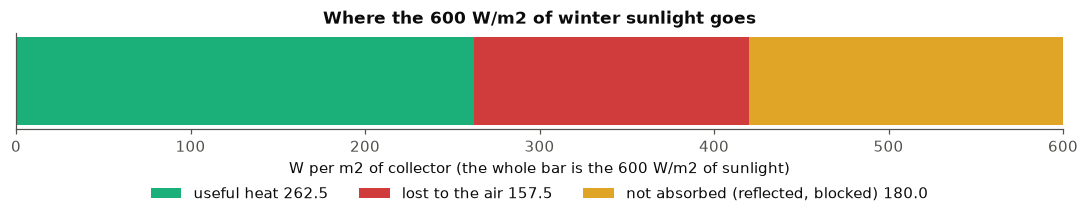

In [2]:
g, ti, ta = WINTER["g_t"], WINTER["t_i"], WINTER["t_a"]
x_a = reduced_temperature(ti, ta, g)
eta_a = efficiency(DOUBLE, x_a)
q_a = useful_power(DOUBLE, g, ti, ta)
absorbed = DOUBLE["f_r_tau_alpha"] * g
lost = DOUBLE["f_r_u_l"] * x_a * g
print(f"(a) x = {x_a:.4f} K m2/W")
print(f"(b) eta = {eta_a:.4f}  ({eta_a:.1%})")
print(f"(c) q_u = {q_a:.1f} W/m2   (absorbed {absorbed:.1f} - lost {lost:.1f})")

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.barh([0], [q_a], color=AQUA, label=f"useful heat {q_a:.1f}")
ax.barh([0], [lost], left=[q_a], color=RED, label=f"lost to the air {lost:.1f}")
ax.barh([0], [g - absorbed], left=[absorbed], color=GOLD, label=f"not absorbed (reflected, blocked) {g - absorbed:.1f}")
ax.set_yticks([]); ax.set_xlim(0, g); ax.grid(False)
ax.set_xlabel("W per m2 of collector (the whole bar is the 600 W/m2 of sunlight)")
ax.set_title("Where the 600 W/m2 of winter sunlight goes")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=3, frameon=False)
plt.tight_layout(); plt.show()

**What this means.**
* **(a) x = 0.075 K·m²/W.** The liquid is 45 degrees hotter than the air and the sun is moderate, so the weather is fairly hard on the collector.
* **(b) Efficiency η = 0.4375, about 44 %.** Of 100 units of sunlight, 70 are absorbed at best, but the loss term takes 26 back, so 44 end up as heat.
* **(c) Useful power q_u = 262.5 W/m².** A 4 m² roof panel would deliver roughly 1 kW, about one electric kettle running all the time.
* In the bar above: of 600 W/m², 180 never get into the plate (reflection and glass), 157.5 leak away to the cold air and 262.5 warm the liquid. The leaking part is more than a third of what the plate absorbed, so the slope matters a lot in winter.

# Q(d): the double-glazed collector against the single-glazed one, each on its own day

**Idea.** The sheet gives the single-glazed collector a milder day: 750 W/m² of sunlight, air at 20 °C, liquid in at 45 °C, and a useful power of 412 W/m². Its extension gives its numbers: intercept **0.75** and slope **6.0 W/(m² K)**. They confirm the 412: the line gives η = 0.55 and 0.55 × 750 = 412.5 W/m².

single-glazed on its own day: x = 0.0333, eta = 0.5500, q_u = 412.5 W/m2 (sheet: 412, eta from sheet = 0.5493)
double-glazed on its own day: x = 0.0750, eta = 0.4375, q_u = 262.5 W/m2
double-glazed placed on the single-glazed day: eta = 0.5833, q_u = 437.5 W/m2
share of the absorbed sunlight lost: single 26.7%, double 37.5%


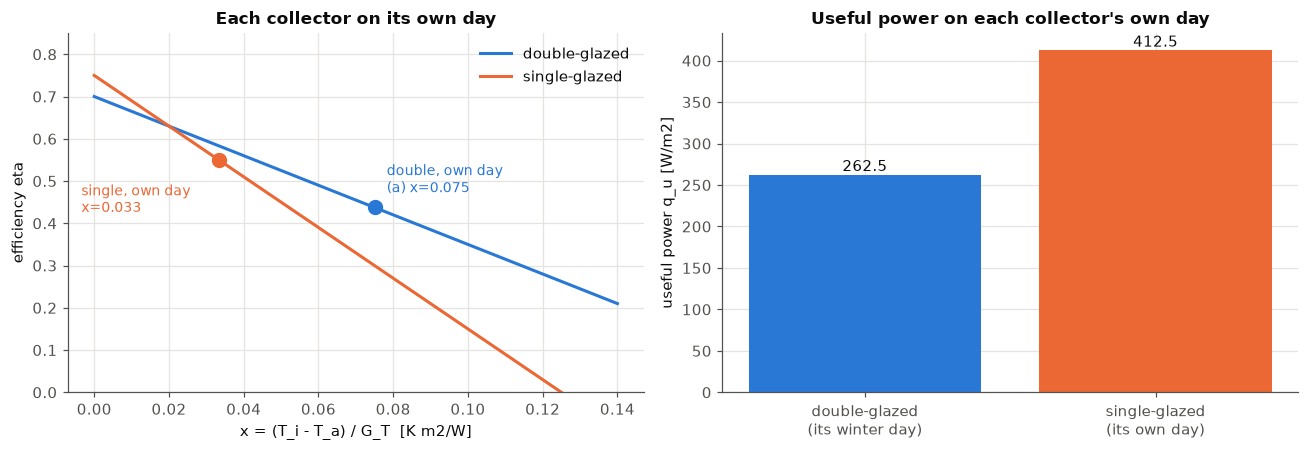

In [3]:
o = SINGLE_OWN
x_s = reduced_temperature(o["t_i"], o["t_a"], o["g_t"])
eta_s = efficiency(SINGLE, x_s)
q_s = useful_power(SINGLE, o["g_t"], o["t_i"], o["t_a"])
eta_d_on_s = efficiency(DOUBLE, x_s)
q_d_on_s = useful_power(DOUBLE, o["g_t"], o["t_i"], o["t_a"])
print(f"single-glazed on its own day: x = {x_s:.4f}, eta = {eta_s:.4f}, q_u = {q_s:.1f} W/m2 (sheet: {o['q_u']:.0f}, eta from sheet = {efficiency_from_power(o['q_u'], o['g_t']):.4f})")
print(f"double-glazed on its own day: x = {x_a:.4f}, eta = {eta_a:.4f}, q_u = {q_a:.1f} W/m2")
print(f"double-glazed placed on the single-glazed day: eta = {eta_d_on_s:.4f}, q_u = {q_d_on_s:.1f} W/m2")
loss_share_s = SINGLE["f_r_u_l"] * x_s / SINGLE["f_r_tau_alpha"]
loss_share_d = DOUBLE["f_r_u_l"] * x_a / DOUBLE["f_r_tau_alpha"]
print(f"share of the absorbed sunlight lost: single {loss_share_s:.1%}, double {loss_share_d:.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(XS, efficiency(DOUBLE, XS), color=BLUE, lw=2, label="double-glazed")
ax[0].plot(XS, efficiency(SINGLE, XS), color=ORANGE, lw=2, label="single-glazed")
ax[0].plot([x_a], [eta_a], "o", color=BLUE, ms=9); ax[0].annotate("double, own day\n(a) x=0.075", (x_a, eta_a), textcoords="offset points", xytext=(8, 10), color=BLUE, fontsize=9)
ax[0].plot([x_s], [eta_s], "o", color=ORANGE, ms=9); ax[0].annotate("single, own day\nx=0.033", (x_s, eta_s), textcoords="offset points", xytext=(-90, -34), color=ORANGE, fontsize=9)
ax[0].set_ylim(0, 0.85); ax[0].set_xlabel("x = (T_i - T_a) / G_T  [K m2/W]"); ax[0].set_ylabel("efficiency eta")
ax[0].set_title("Each collector on its own day"); ax[0].legend(frameon=False)
names = ["double-glazed\n(its winter day)", "single-glazed\n(its own day)"]
vals = [q_a, q_s]
ax[1].bar(names, vals, color=[BLUE, ORANGE]); ax[1].bar_label(ax[1].containers[0], fmt="%.1f", fontsize=10)
ax[1].set_ylabel("useful power q_u [W/m2]"); ax[1].set_title("Useful power on each collector's own day")
plt.tight_layout(); plt.show()

**What this means.**
* **The single-glazed collector wins on its own day: 412 W/m² against 262.5 W/m²**, an efficiency of 55 % against 44 %.
* **Why, in physical terms.** On the mild day $x$ is small (0.033), so the leak term is only 6.0 × 0.033 = 0.20, about 27 % of what the plate absorbs. The collector's **intercept** does the work: its 0.75 is higher than the double-glazed 0.70. In the cold winter day $x$ is more than twice as big (0.075), so the double-glazed collector loses 37.5 % of what its plate absorbs. There its **slope** is what keeps it going: a slope of 3.5 instead of 6.0 saves a lot.
* **Careful: the weather, not the collector, won this round.** Put the double-glazed collector on the single-glazed collector's mild day and it would give η = 0.583 and **437.5 W/m²**, more than the 412. The single-glazed collector only "wins" because its day is far easier. A fair match needs the same weather, which is the next question.

# Q(e): both collectors on the same winter afternoon

**Idea.** Same sun, same air, same liquid temperature: 600 W/m², 5 °C and 50 °C, so $x = 0.075$ for both.

winter day (G_T=600, T_i=50, T_a=5):  double eta = 0.4375, q_u = 262.5 W/m2;  single eta = 0.3000, q_u = 180.0 W/m2
better: double-glazed, selective coating, by a factor 1.46


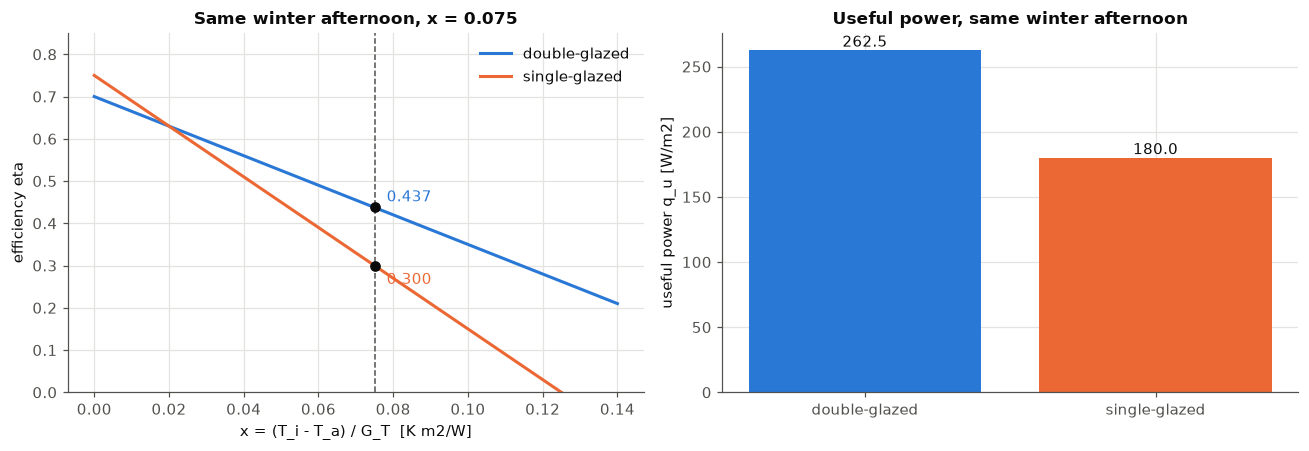

In [4]:
q_s_win = useful_power(SINGLE, g, ti, ta)
eta_s_win = efficiency(SINGLE, x_a)
print(f"winter day (G_T={g:.0f}, T_i={ti:.0f}, T_a={ta:.0f}):  double eta = {eta_a:.4f}, q_u = {q_a:.1f} W/m2;  single eta = {eta_s_win:.4f}, q_u = {q_s_win:.1f} W/m2")
print(f"better: {better_collector(DOUBLE, SINGLE, x_a)['name']}, by a factor {q_a / q_s_win:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(XS, efficiency(DOUBLE, XS), color=BLUE, lw=2, label="double-glazed")
ax[0].plot(XS, efficiency(SINGLE, XS), color=ORANGE, lw=2, label="single-glazed")
ax[0].axvline(x_a, color=MUTED, ls="--", lw=1)
ax[0].plot([x_a, x_a], [eta_a, eta_s_win], "o", color=INK)
ax[0].annotate(f"{eta_a:.3f}", (x_a, eta_a), textcoords="offset points", xytext=(8, 4), color=BLUE)
ax[0].annotate(f"{eta_s_win:.3f}", (x_a, eta_s_win), textcoords="offset points", xytext=(8, -12), color=ORANGE)
ax[0].set_ylim(0, 0.85); ax[0].set_xlabel("x = (T_i - T_a) / G_T  [K m2/W]"); ax[0].set_ylabel("efficiency eta")
ax[0].set_title("Same winter afternoon, x = 0.075"); ax[0].legend(frameon=False)
ax[1].bar(["double-glazed", "single-glazed"], [q_a, q_s_win], color=[BLUE, ORANGE]); ax[1].bar_label(ax[1].containers[0], fmt="%.1f", fontsize=10)
ax[1].set_ylabel("useful power q_u [W/m2]"); ax[1].set_title("Useful power, same winter afternoon")
plt.tight_layout(); plt.show()

**What this means.**
* **The double-glazed collector is better, by a factor of 1.46:** 262.5 W/m² against 180 W/m², or 44 % against 30 % efficiency.
* The single-glazed collector has the higher intercept (0.75), but its steep slope (6.0) takes 0.45 away at x = 0.075, leaving only 0.30. The double-glazed collector loses 0.2625 and keeps 0.4375.
* **The intercept alone would give the wrong answer.** Always look at the actual operating point.

# Q(f): where do the two lines cross?

**Idea.** At the crossing the two collectors are equally efficient. Set the two lines equal and solve for $x$.

> **Crossing point**: the value of $x$ where the efficiencies of two collectors are equal. On one side one collector is better, on the other side the other.

crossing at x = 0.0200 K m2/W, where both have eta = 0.630
below it: single-glazed; above it: double-glazed, selective coating
G_T =  600 W/m2: crossing at a fluid-to-air difference of 12.0 K
G_T =  750 W/m2: crossing at a fluid-to-air difference of 15.0 K
G_T = 1000 W/m2: crossing at a fluid-to-air difference of 20.0 K


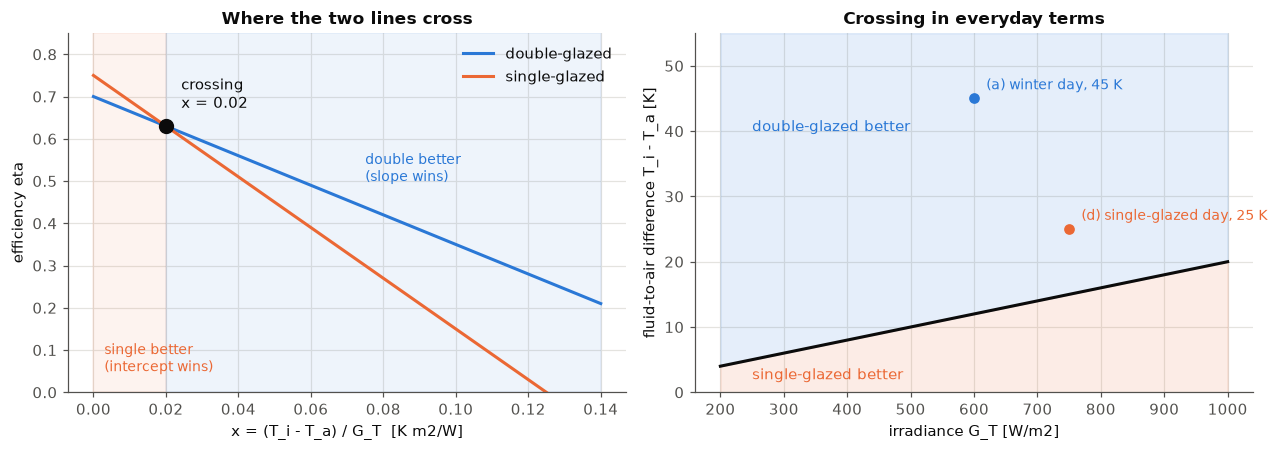

In [5]:
x_c = crossing(DOUBLE, SINGLE)
eta_c = efficiency(DOUBLE, x_c)
print(f"crossing at x = {x_c:.4f} K m2/W, where both have eta = {eta_c:.3f}")
print(f"below it: {better_collector(DOUBLE, SINGLE, x_c / 2)['name']}; above it: {better_collector(DOUBLE, SINGLE, x_c * 2)['name']}")
for g_ in (600, 750, 1000):
    print(f"G_T = {g_:4d} W/m2: crossing at a fluid-to-air difference of {x_c * g_:.1f} K")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(XS, efficiency(DOUBLE, XS), color=BLUE, lw=2, label="double-glazed")
ax[0].plot(XS, efficiency(SINGLE, XS), color=ORANGE, lw=2, label="single-glazed")
ax[0].axvspan(0, x_c, color=ORANGE, alpha=0.08); ax[0].axvspan(x_c, XS[-1], color=BLUE, alpha=0.08)
ax[0].plot([x_c], [eta_c], "o", color=INK, ms=9)
ax[0].annotate(f"crossing\nx = {x_c:.2f}", (x_c, eta_c), textcoords="offset points", xytext=(10, 12))
ax[0].text(0.003, 0.05, "single better\n(intercept wins)", color=ORANGE, fontsize=9)
ax[0].text(0.075, 0.50, "double better\n(slope wins)", color=BLUE, fontsize=9)
ax[0].set_ylim(0, 0.85); ax[0].set_xlabel("x = (T_i - T_a) / G_T  [K m2/W]"); ax[0].set_ylabel("efficiency eta")
ax[0].set_title("Where the two lines cross"); ax[0].legend(frameon=False, loc="upper right")
gs = np.linspace(200, 1000, 50)
ax[1].plot(gs, x_c * gs, color=INK, lw=2)
ax[1].fill_between(gs, 0, x_c * gs, color=ORANGE, alpha=0.12); ax[1].fill_between(gs, x_c * gs, 55, color=BLUE, alpha=0.12)
ax[1].text(250, 2, "single-glazed better", color=ORANGE); ax[1].text(250, 40, "double-glazed better", color=BLUE)
for g_, d_, lab, col in ((600, 45, "(a) winter day, 45 K", BLUE), (750, 25, "(d) single-glazed day, 25 K", ORANGE)):
    ax[1].plot([g_], [d_], "o", color=col); ax[1].annotate(lab, (g_, d_), textcoords="offset points", xytext=(8, 6), color=col, fontsize=9)
ax[1].set_ylim(0, 55); ax[1].set_xlabel("irradiance G_T [W/m2]"); ax[1].set_ylabel("fluid-to-air difference T_i - T_a [K]")
ax[1].set_title("Crossing in everyday terms")
plt.tight_layout(); plt.show()

**What this means.**
* **The lines cross at x = 0.02 K·m²/W**, where both collectors have an efficiency of 0.63.
* **Below x = 0.02 the single-glazed collector is better** (the intercept wins when losses are small). **Above it the double-glazed collector is better** (the slope wins when losses are big).
* In everyday terms: at 600 W/m² the crossing is at a difference of only **12 K** between liquid and air, at 750 W/m² at 15 K. A collector that heats a swimming pool, a few degrees above the air, belongs to the single-glazed side. A collector that heats a house in winter, 45 K above the air, belongs to the double-glazed side.
* All the cases of this lab sit above the crossing (x = 0.075 and x = 0.033), so in a fair comparison the double-glazed collector would win in both.

# Summary

* **(a)** x = 0.075 K·m²/W. **(b)** η = 0.4375. **(c)** q_u = 262.5 W/m².
* **(d)** On its own day the single-glazed collector gives more (412 W/m²) because its day is mild and its intercept does the work. On a cold day the slope matters and the double-glazed collector keeps more of the sun.
* **(e)** On the same winter afternoon the double-glazed collector gives 262.5 W/m² against 180 W/m².
* **(f)** The lines cross at x = 0.02 K·m²/W: below it the single-glazed collector is better, above it the double-glazed one.
* **Never judge two collectors by the intercept alone: check the actual operating point.**